price_sentiment_impact

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
path="../data/processed/AAPL_price_sentiment_features.csv"
df=pd.read_csv(path, parse_dates=["Date"])
df=df.set_index("Date").sort_index()
import sys
from pathlib import Path

# Add project root to PYTHONPATH
project_root = Path("..").resolve()
sys.path.append(str(project_root))

print(project_root)

df.head()


D:\lessons\season 4\code\stock-transformer-project


,Open,High,Low,Close,Volume,log_return,vol_20,sentiment_mean,news_count,relevance_mean
Date,,,,,,,,,,
2015-01-02,27.847500,27.860001,26.837500,27.332500,212818400,NaN,NaN,0.0,0.0,0.0
2015-01-05,27.072500,27.162500,26.352501,26.562500,257142000,-0.028576,NaN,0.0,0.0,0.0
2015-01-06,26.635000,26.857500,26.157499,26.565001,263188400,0.000094,NaN,0.0,0.0,0.0
2015-01-07,26.799999,27.049999,26.674999,26.937500,160423600,0.013925,NaN,0.0,0.0,0.0
2015-01-08,27.307501,28.037500,27.174999,27.972500,237458000,0.037703,NaN,0.0,0.0,0.0


In this notebook, we analyze the relationship between daily stock prices and news sentiment.
Due to limited temporal overlap between price and sentiment data, sentiment analysis is first examined independently.

In [8]:
df["news_count"].describe()

count    2763.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: news_count, dtype: float64

In [10]:
df_news=df[df["news_count"]> 0].copy()
df_news.len()

AttributeError: 'DataFrame' object has no attribute 'len'

The sentiment data retrieved from Alpha Vantage covers dates after the last available trading day in the price dataset.
Therefore, no overlapping dates exist between the two datasets at this stage.

In [13]:
from src.sentiment_collection import fetch_news_sentiment, news_json_to_df
from dotenv import load_dotenv
import os
load_dotenv()
api=os.getenv("ALPHAVANTAGE_API_KEY")
data=fetch_news_sentiment (api_key=api, tickers="AAPL", limit=50)
sent_df= news_json_to_df (data, target_ticker="AAPL")
sent_df.head()

,time_published,title,source,sentiment_score,relevance_score
0,2026-01-17 14:21:00,Costco Switches Food Court Back to Coke After ...,Yahoo Finance,0.128253,0.634313
1,2026-01-17 14:25:48,Apple stock slides into earnings: why AAPL tra...,TechStock²,-0.237763,1.000000
2,2026-01-17 15:27:35,Investors Worried About Large Cap Concentratio...,24/7 Wall St.,-0.107468,0.579773
3,2026-01-17 15:28:19,A Focused Approach to Developed Markets: Analy...,AD HOC NEWS,0.337567,0.558719
4,2026-01-17 16:57:16,Balancing Growth and Income: A Look at the Glo...,AD HOC NEWS,0.327697,0.619053


In [14]:
sent_df= sent_df.copy()
sent_df["Date"]=sent_df["time_published"].dt.floor("D")
sent_df.head()

,time_published,title,source,sentiment_score,relevance_score,Date
0,2026-01-17 14:21:00,Costco Switches Food Court Back to Coke After ...,Yahoo Finance,0.128253,0.634313,2026-01-17
1,2026-01-17 14:25:48,Apple stock slides into earnings: why AAPL tra...,TechStock²,-0.237763,1.000000,2026-01-17
2,2026-01-17 15:27:35,Investors Worried About Large Cap Concentratio...,24/7 Wall St.,-0.107468,0.579773,2026-01-17
3,2026-01-17 15:28:19,A Focused Approach to Developed Markets: Analy...,AD HOC NEWS,0.337567,0.558719,2026-01-17
4,2026-01-17 16:57:16,Balancing Growth and Income: A Look at the Glo...,AD HOC NEWS,0.327697,0.619053,2026-01-17


In [16]:
daily_sent=(sent_df. groupby("Date").agg ( 
            sentiment_mean=("sentiment_score", "mean"),
        sentiment_std=("sentiment_score", "std"),
        news_count=("sentiment_score", "size"),
        relevance_mean=("relevance_score", "mean")))
daily_sent

,sentiment_mean,sentiment_std,news_count,relevance_mean
Date,,,,
2026-01-17,0.089657,0.257718,5,0.678372
2026-01-18,0.175371,0.124924,13,0.679519
2026-01-19,0.154123,0.279251,30,0.782297
2026-01-20,-0.054819,0.277387,2,0.784671


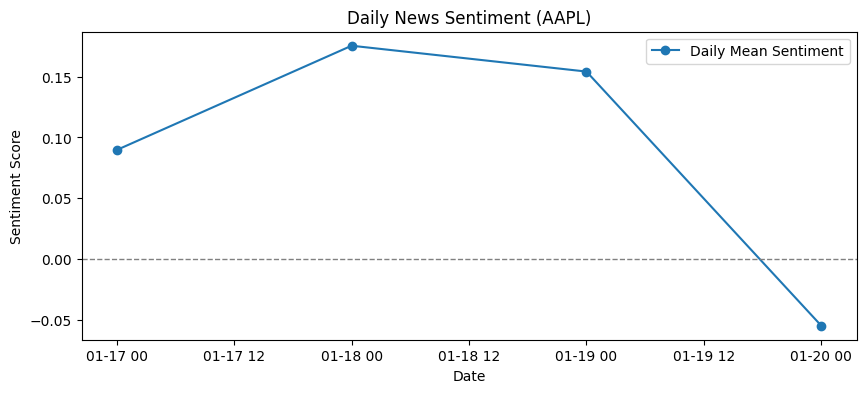

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    daily_sent.index,
    daily_sent["sentiment_mean"],
    marker="o",
    linestyle="-",
    label="Daily Mean Sentiment"
)

ax.axhline(0, linestyle="--", color="gray", linewidth=1)

ax.set_title("Daily News Sentiment (AAPL)")
ax.set_ylabel("Sentiment Score")
ax.set_xlabel("Date")
ax.legend()

plt.show()

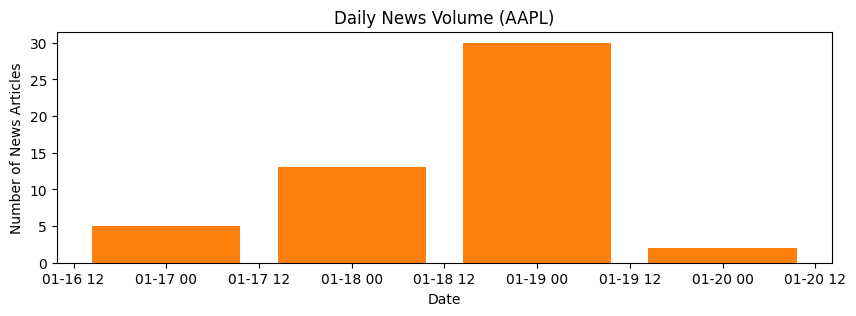

In [18]:
fig, ax = plt.subplots(figsize=(10, 3))

ax.bar(
    daily_sent.index,
    daily_sent["news_count"],
    color="tab:orange"
)

ax.set_title("Daily News Volume (AAPL)")
ax.set_ylabel("Number of News Articles")
ax.set_xlabel("Date")

plt.show()
